<a href="https://colab.research.google.com/github/alexbedoni95-cpu/Analisi-Climatica-UE-e-Modellazione-Predittiva-2035-Progetto-Finale-EEA-/blob/main/Progetto_finale_aulab_richiesta_5_parte_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TypeError: 'value' must be an instance of str or bytes, not a float

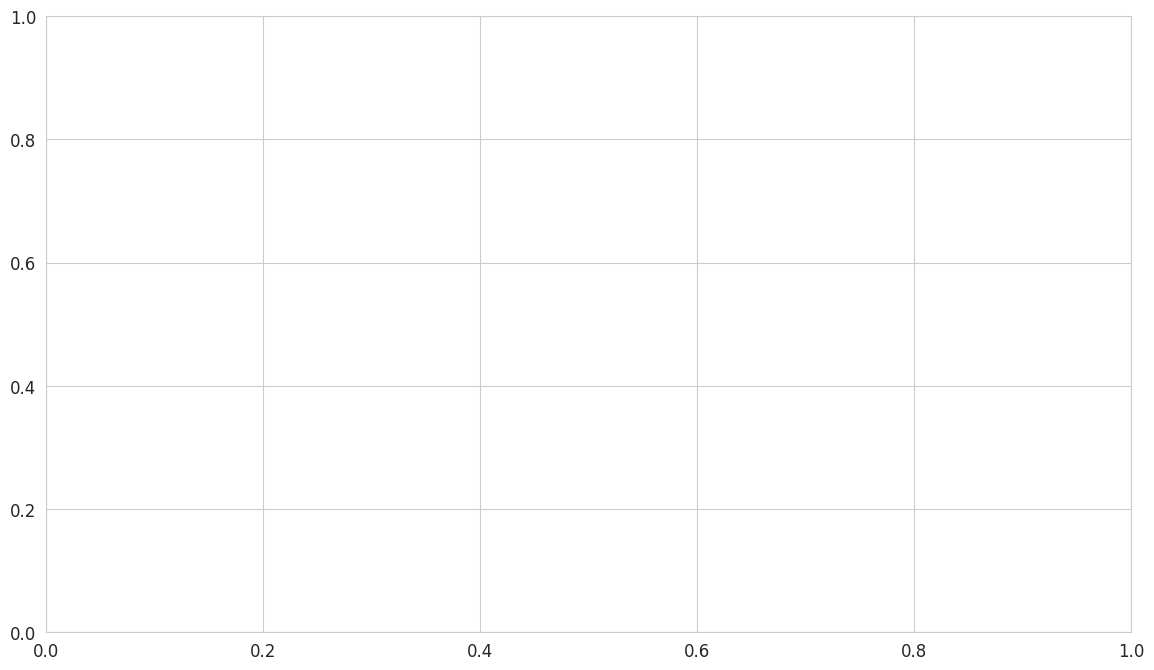

In [ ]:
# Melt the DataFrame to plot all emissions on the same y-axis
df_plot = df_merged.melt(
    id_vars=['Country', 'Year', 'Renewable_Electricity_Production_Percentage'],
    value_vars=[
        'CO2_Emissions_kt', 'CH4_Emissions_kt', 'N2O_Emissions_kt',
        'SO2_Emissions_kt', 'NOx_Emissions_kt'
    ],
    var_name='Gas_Type',
    value_name='Emissions_kt'
)

# Ensure Emissions_kt is numeric and Gas_Type is string
df_plot['Emissions_kt'] = pd.to_numeric(df_plot['Emissions_kt'], errors='coerce')
df_plot['Gas_Type'] = df_plot['Gas_Type'].astype(str)
df_plot.dropna(subset=['Emissions_kt', 'Renewable_Electricity_Production_Percentage'], inplace=True) # Also drop NaNs from X-axis

# Define markers for each gas type
gas_markers = {
    'CO2_Emissions_kt': 'o',  # Circle
    'CH4_Emissions_kt': 's',  # Square
    'N2O_Emissions_kt': '^',  # Triangle up
    'SO2_Emissions_kt': 'D',  # Diamond
    'NOx_Emissions_kt': 'X'   # X (filled)
}

# Define the order of styles to ensure consistency and prevent type errors
style_order = list(gas_markers.keys())

plt.figure(figsize=(14, 8))
sns.scatterplot(
    data=df_plot,
    x='Renewable_Electricity_Production_Percentage',
    y='Emissions_kt',
    hue='Gas_Type',
    style='Gas_Type', # Use different markers for different gas types
    markers=gas_markers, # Explicitly define markers
    style_order=style_order, # Explicitly define style order
    size='Emissions_kt', # Size points by emission quantity
    sizes=(50, 600), # Range of point sizes
    alpha=0.7
)

plt.title('Correlazione tra Produzione di Energia Rinnovabile e Emissioni di Gas Serra nell\'UE',
          fontsize=16, pad=20)
plt.xlabel('Produzione di Energia Rinnovabile (Percentuale Normalizzata)', fontsize=14)
plt.ylabel('Emissioni (Migliaia di Tonnellate)', fontsize=14)
plt.legend(title='Tipo di Gas', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=12, title_fontsize=13)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()